# dat_gen

In [ ]:
import os
import pandas as pd
import wfdb
import numpy as np
from scipy import signal as scipy_signal
import traceback

def convert_and_align_to_wfdb():
    # ================= 1. 路徑設定 =================
    base_dir = r'C:\Users\USER\Desktop\test_env\dataset'
    
    # 輸入路徑
    ecg_csv_folder = os.path.join(base_dir, 'ECG')
    pcg_csv_folder = os.path.join(base_dir, 'PCG')
    # 修改為讀取 REF.csv
    ref_sd_path = os.path.join(base_dir, 'REF', 'REF.csv') 
    
    # 輸出路徑
    output_ecg_dir = os.path.join(base_dir, 'A_output', 'ECG_DAT1')
    output_pcg_dir = os.path.join(base_dir, 'A_output', 'PCG_DAT1')
    error_log_path = os.path.join(base_dir, 'A_output', 'error_log_sync.txt')
    
    # 建立輸出資料夾
    for d in [output_ecg_dir, output_pcg_dir]:
        if not os.path.exists(d):
            os.makedirs(d)

    print(f"Reading Reference: {ref_sd_path}")

    # ================= 2. 讀取 REF 表單 =================
    if not os.path.exists(ref_sd_path):
        print(f"Error: REF file not found at {ref_sd_path}")
        return

    try:
        df_ref = pd.read_csv(ref_sd_path)
        df_ref.columns = [c.strip() for c in df_ref.columns]
        
        # 確保必要欄位存在 (已移除 delay 與 mult)
        if 'start' not in df_ref.columns: df_ref['start'] = 0
            
        print(f"Total rows to process: {len(df_ref)}")
        
    except Exception as e:
        print(f"Error reading reference file: {e}")
        return

    success_count = 0
    fail_count = 0
    error_details = []
    
    # ================= 3. 逐筆處理 (同時處理 ECG 與 PCG) =================
    for idx, row in df_ref.iterrows():
        raw_filename = str(row['file']).strip()
        
        # --- 參數擷取 ---
        try: start_val = float(row['start'])
        except: start_val = 0.0
            
        try: ecg_fs = int(row.get('ecg_sr', 360))
        except: ecg_fs = 360
            
        try: pcg_fs = int(row.get('pcg_sr', 1950))
        except: pcg_fs = 1950
        
        # 處理 end 欄位 (可能為空值或 NaN)
        try:
            if pd.notna(row.get('end')) and str(row.get('end')).strip() != '' and str(row.get('end')).lower() != 'nan':
                end_val = float(row['end'])
            else:
                end_val = None
        except:
            end_val = None

        # --- 檔名設定 ---
        if not raw_filename.endswith('.csv'):
            csv_filename = raw_filename + '.csv'
            record_name = raw_filename
        else:
            csv_filename = raw_filename
            record_name = raw_filename[:-4]
            
        ecg_path = os.path.join(ecg_csv_folder, csv_filename)
        pcg_path = os.path.join(pcg_csv_folder, csv_filename)

        # 檢查檔案是否存在
        if not os.path.exists(ecg_path) or not os.path.exists(pcg_path):
            error_msg = f"Missing file: ECG({os.path.exists(ecg_path)}) / PCG({os.path.exists(pcg_path)})"
            print(f"Warning: {csv_filename} - {error_msg}. Skipping.")
            error_details.append(f"{csv_filename} - {error_msg}")
            fail_count += 1
            continue

        try:
            # ================= [ECG 處理區塊] =================
            data_ecg = pd.read_csv(ecg_path, header=None, dtype=str).values.flatten()
            int_vals_ecg = [int(str(x).strip().replace("'", "").replace('"', ''), 16) if pd.notna(x) else 0 for x in data_ecg]
            arr_ecg = np.array(int_vals_ecg, dtype=np.int32)
            arr_ecg[arr_ecg > 32767] -= 65536
            
            # ECG Offset 與 Filter
            ecg_offset_samples = int(ecg_fs * start_val)
            if ecg_offset_samples >= len(arr_ecg): raise ValueError(f"ECG Offset {ecg_offset_samples} >= Length {len(arr_ecg)}")
            
            nyquist = ecg_fs / 2
            high_cut = 80 if nyquist > 80 else nyquist - 1
            fir1 = scipy_signal.firwin(207, [0.5, high_cut], fs=ecg_fs, window='hamming', pass_zero=False)
            ecg_fir = scipy_signal.lfilter(fir1, 1, arr_ecg)
            
            if ecg_offset_samples > 0:
                ecg_fir = ecg_fir[ecg_offset_samples:]

            # ================= [PCG 處理區塊] =================
            data_pcg = pd.read_csv(pcg_path, header=None, dtype=str).values.flatten()
            int_vals_pcg = [int(str(x).strip().replace("'", "").replace('"', ''), 16) if pd.notna(x) and str(x).lower() != 'nan' else 0 for x in data_pcg]
            arr_pcg = np.array(int_vals_pcg, dtype=np.int32)
            arr_pcg[arr_pcg > 32767] -= 65536
            
            # PCG Offset 與 Filter  
            pcg_offset_samples = int(pcg_fs * start_val)
            if pcg_offset_samples < 0: pcg_offset_samples = 0
            if pcg_offset_samples >= len(arr_pcg): raise ValueError(f"PCG Offset {pcg_offset_samples} >= Length {len(arr_pcg)}")
            
            fir_num = int((207 * pcg_fs) / 360)
            if fir_num % 2 == 0: fir_num += 1
            fir2 = scipy_signal.firwin(fir_num, [30], fs=pcg_fs, window='hamming', pass_zero=False)
            pcg_fir = scipy_signal.lfilter(fir2, 1, arr_pcg)
            
            if pcg_offset_samples > 0:
                pcg_fir = pcg_fir[pcg_offset_samples:]

            # ================= [對齊、裁切核心邏輯] =================
            # 1. 計算雙方轉換後可用的最大秒數
            ecg_sec_raw = len(ecg_fir) / ecg_fs
            pcg_sec_raw = len(pcg_fir) / pcg_fs
            
            # 取雙方都能滿足的最短秒數，避免某一方資料空白，並以 0.1 秒向下取整
            common_sec = min(ecg_sec_raw, pcg_sec_raw)
            common_sec = np.floor(common_sec * 10) / 10.0
            
            # 2. 判斷是否有給定 end 參數
            final_sec = common_sec
            if end_val is not None and end_val > 0:
                final_sec = min(common_sec, end_val)

            # 印出裁切資訊
            print(f"[{csv_filename}] ECG:{ecg_sec_raw:.2f}s, PCG:{pcg_sec_raw:.2f}s -> Final Target: {final_sec}s")

            # 3. 套用最終長度 (移除原有的 PCG numpy 插值)
            # ECG 裁切
            ecg_target_len = int(final_sec * ecg_fs)
            ecg_final = ecg_fir[:ecg_target_len]

            # PCG 裁切
            pcg_target_len = int(final_sec * pcg_fs)
            pcg_final = pcg_fir[:pcg_target_len]

            # ================= [寫入 WFDB] =================
            # 確保有資料才寫入
            if len(ecg_final) == 0 or len(pcg_final) == 0:
                raise ValueError(f"Final truncated signal is empty (final_sec={final_sec})")

            # 轉回 int32 並重塑為 2D array (WFDB 寫入需求)
            ecg_signal_final = np.round(ecg_final).astype(np.int32).reshape(-1, 1)
            pcg_signal_final = np.round(pcg_final).astype(np.int32).reshape(-1, 1)

            # 寫入 ECG
            wfdb.wrsamp(
                record_name=record_name, fs=ecg_fs, units=['mV'], sig_name=['ECG'],
                d_signal=ecg_signal_final, fmt=['16'], adc_gain=[1.0], baseline=[0], write_dir=output_ecg_dir
            )
            
            # 寫入 PCG
            wfdb.wrsamp(
                record_name=record_name, fs=pcg_fs, units=['mV'], sig_name=['PCG'],
                d_signal=pcg_signal_final, fmt=['16'], adc_gain=[1.0], baseline=[0], write_dir=output_pcg_dir
            )

            success_count += 1
            if success_count % 10 == 0:
                print(f"Processed {success_count} records successfully...")
            
        except pd.errors.EmptyDataError:
            error_msg = "Empty CSV file"
            print(f"[FAILED] {csv_filename}: {error_msg}")
            error_details.append(f"{csv_filename} - {error_msg}")
            fail_count += 1
            
        except Exception as e:
            error_trace = traceback.format_exc()
            print(f"[FAILED] Error converting {csv_filename}: {e}")
            error_details.append(f"=== {csv_filename} ===\n{error_trace}\n")
            fail_count += 1

    # ================= 4. 總結與匯出錯誤日誌 =================
    print(f"\n=== Conversion & Sync Summary ===")
    print(f"Success: {success_count}")
    print(f"Failed: {fail_count}")
    print(f"ECG Check output in: {output_ecg_dir}")
    print(f"PCG Check output in: {output_pcg_dir}")
    
    if fail_count > 0:
        try:
            with open(error_log_path, 'w', encoding='utf-8') as f:
                f.write(f"Total Failed: {fail_count}\n")
                f.write("="*30 + "\n")
                for err in error_details:
                    f.write(err + "\n")
            print(f"[Info] Detailed error log saved to: {error_log_path}")
        except Exception as write_err:
            print(f"Failed to write error log: {write_err}")

if __name__ == "__main__":
    convert_and_align_to_wfdb()

# WAV_gen


In [ ]:
import os
import pandas as pd
import numpy as np
from scipy.io import wavfile
import wfdb

def wfdb_to_wav_conversion(record_path, output_wav_path):
    """
    核心轉換函數：讀取 WFDB 格式，直接轉為 WAV。 
    """
    try: 
        record = wfdb.rdrecord(record_path, physical=False)
         
        audio_data = record.d_signal[:, 0]
        fs = record.fs
         
        audio_data_int16 = np.clip(audio_data, -32768, 32767).astype(np.int16)
         
        wavfile.write(output_wav_path, fs, audio_data_int16)
        return True, fs
        
    except Exception as e:
        print(f"  [Error] WFDB 讀取或轉換失敗: {e}")
        return False, 0

def batch_process_wfdb_to_wav(): 
    base_dir = r'C:\Users\USER\Desktop\test_env\dataset' 
    ref_csv_path = os.path.join(base_dir, 'REF', 'REF.csv') 
    input_dir = os.path.join(base_dir, 'A_output', 'PCG_DAT') 
    output_dir = os.path.join(base_dir, 'A_output', 'PCG_WAV')
    # =========================================== 
    if not os.path.exists(output_dir):
        os.makedirs(output_dir)
        print(f"已建立輸出資料夾: {output_dir}")
 
    if not os.path.exists(ref_csv_path):
        print(f"錯誤: 找不到參考檔 {ref_csv_path}")
        return

    print(f"正在讀取清單: {ref_csv_path} ...")
    
    try:
        df_ref = pd.read_csv(ref_csv_path)
        df_ref.columns = [c.strip() for c in df_ref.columns]
    except Exception as e:
        print(f"讀取參考檔失敗: {e}")
        return

    print(f"共發現 {len(df_ref)} 筆資料，開始處理...\n")

    success_count = 0
    fail_count = 0
 
    for index, row in df_ref.iterrows(): 
        raw_filename = str(row['file']).strip()
        if raw_filename.lower().endswith('.csv'):
            record_name = raw_filename[:-4]
        else:
            record_name = raw_filename
             
        record_path = os.path.join(input_dir, record_name)
         
        wav_filename = record_name + '.wav'
        output_path = os.path.join(output_dir, wav_filename)
 
        if not os.path.exists(record_path + '.hea'):
            print(f"跳過: 找不到 WFDB 檔案 ({record_name}.hea)")
            fail_count += 1
            continue
 
        success, fs = wfdb_to_wav_conversion(record_path, output_path)
        if success:
            print(f"轉換成功: {record_name} -> {wav_filename} (SR: {fs}Hz)")
            success_count += 1
        else:
            fail_count += 1

    print("\n" + "="*30)
    print(f"處理完成 Summary:")
    print(f"成功: {success_count} 筆")
    print(f"失敗/跳過: {fail_count} 筆")
    print(f"檔案已儲存至: {output_dir}")
    print("="*30)

if __name__ == "__main__":
    batch_process_wfdb_to_wav()

已建立輸出資料夾: C:\Users\USER\Desktop\test_env\dataset\A_output\PCG_WAV
正在讀取清單: C:\Users\USER\Desktop\test_env\dataset\REF\REF3.csv ...
共發現 1596 筆資料，開始處理...

轉換成功: 2024_09_30_09_15_51 -> 2024_09_30_09_15_51.wav (SR: 1000Hz)
轉換成功: 2024_09_30_09_17_00 -> 2024_09_30_09_17_00.wav (SR: 1000Hz)
轉換成功: 2024_09_30_09_29_03 -> 2024_09_30_09_29_03.wav (SR: 1000Hz)
轉換成功: 2024_09_30_09_29_54 -> 2024_09_30_09_29_54.wav (SR: 1000Hz)
轉換成功: 2024_09_30_10_25_33 -> 2024_09_30_10_25_33.wav (SR: 1000Hz)
轉換成功: 2024_09_30_10_25_52 -> 2024_09_30_10_25_52.wav (SR: 1000Hz)
轉換成功: 2024_09_30_10_26_19 -> 2024_09_30_10_26_19.wav (SR: 1000Hz)
轉換成功: 2024_09_30_10_26_42 -> 2024_09_30_10_26_42.wav (SR: 1000Hz)
轉換成功: 2024_09_30_11_24_37 -> 2024_09_30_11_24_37.wav (SR: 1000Hz)
轉換成功: 2024_09_30_11_24_57 -> 2024_09_30_11_24_57.wav (SR: 1000Hz)
轉換成功: 2024_09_30_11_25_16 -> 2024_09_30_11_25_16.wav (SR: 1000Hz)
轉換成功: 2024_09_30_11_25_37 -> 2024_09_30_11_25_37.wav (SR: 1000Hz)
轉換成功: 2024_09_30_13_56_02 -> 2024_09_30_13_56_02.wav (SR

# sec_PCGvsECG_mismatch

In [ ]:
import os
import wfdb
import pandas as pd

def check_duration_mismatch(threshold_sec=2.0):
    # ================= 1. 路徑設定 =================
    base_dir = r'C:\Users\USER\Desktop\test_env\dataset' # 請依需求調整
    ecg_dat_dir = os.path.join(base_dir, 'P', 'ECG')
    pcg_dat_dir = os.path.join(base_dir, 'P', 'PCG')
    output_report_path = os.path.join(base_dir, 'A_output', 'mismatch_report.csv')
    
    if not os.path.exists(ecg_dat_dir) or not os.path.exists(pcg_dat_dir):
        print("Error: ECG_DAT 或 PCG_DAT 資料夾不存在，請確認路徑。")
        return

    # 取得 ECG 資料夾內所有的 .hea 檔案
    ecg_files = [f for f in os.listdir(ecg_dat_dir) if f.endswith('.hea')]
    
    if not ecg_files:
        print("沒有找到任何 .hea 檔案。")
        return

    print(f"開始掃描比對，共發現 {len(ecg_files)} 筆潛在檔案...")
    
    mismatch_list = []
    missing_pcg_count = 0

    # ================= 2. 逐一比對表頭 (Header) =================
    for file in ecg_files:
        record_name = file.replace('.hea', '')
        
        ecg_record_path = os.path.join(ecg_dat_dir, record_name)
        pcg_record_path = os.path.join(pcg_dat_dir, record_name)
        
        # 檢查 PCG 檔案是否存在
        if not os.path.exists(pcg_record_path + '.hea'):
            missing_pcg_count += 1
            continue
            
        try:
            # 💡 技巧：使用 rdheader 只讀取表頭，速度比 rdrecord 快非常多！
            ecg_header = wfdb.rdheader(ecg_record_path)
            pcg_header = wfdb.rdheader(pcg_record_path)
            
            # 計算實際時長 = 總資料點數 (sig_len) / 取樣頻率 (fs)
            ecg_duration = ecg_header.sig_len / ecg_header.fs
            pcg_duration = pcg_header.sig_len / pcg_header.fs
            
            # 計算時間差 (取絕對值)
            time_diff = abs(ecg_duration - pcg_duration)
            
            # 若相差大於或等於我們設定的閾值
            if time_diff >= threshold_sec:
                mismatch_list.append({
                    'Record': record_name,
                    'ECG_Duration (s)': round(ecg_duration, 3),
                    'PCG_Duration (s)': round(pcg_duration, 3),
                    'Difference (s)': round(time_diff, 3)
                })
                
        except Exception as e:
            print(f"讀取 {record_name} 時發生錯誤: {e}")

    # ================= 3. 輸出結果 =================
    print("\n" + "="*40)
    print(f"掃描完成！")
    print(f"缺少對應 PCG 的檔案數: {missing_pcg_count}")
    
    if len(mismatch_list) == 0:
        print(f"🎉 太棒了！沒有發現相差超過 {threshold_sec} 秒的資料。")
    else:
        print(f"⚠️ 發現 {len(mismatch_list)} 筆資料相差超過 {threshold_sec} 秒：\n")
        
        # 將結果轉為 DataFrame 方便顯示與存檔
        df_mismatch = pd.DataFrame(mismatch_list)
        
        # ================= [修改點：改為依照檔名排序] =================
        # ascending=True 代表由 A 到 Z（或數字由小到大）正向排序
        df_mismatch = df_mismatch.sort_values(by='Record', ascending=True).reset_index(drop=True)
        # =============================================================
        
        # 印出表格
        print(df_mismatch.to_string())
        
        # 存成 CSV 報告
        df_mismatch.to_csv(output_report_path, index=False, encoding='utf-8')
        print(f"\n📁 差異報告已儲存至: {output_report_path}")
    print("="*40)

if __name__ == "__main__":
    # 執行掃描，找出差異超過 3.0 秒的資料
    check_duration_mismatch(0.2)

開始掃描比對，共發現 1596 筆潛在檔案...

掃描完成！
缺少對應 PCG 的檔案數: 0
🎉 太棒了！沒有發現相差超過 0.2 秒的資料。


In [6]:
import os
import wfdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# [修改點 1] 將參數移到函式的括號內，並設定預設值
def verify_multiple_records_fixed_axis(start_index, check_count, chunk_size=5.0):
    # ================= 1. 路徑設定 =================
    base_dir = r'C:\Users\USER\Desktop\test_env\dataset' # 請依需求調整
    ref_csv_path = os.path.join(base_dir, 'P','REF.csv')
    ecg_dat_dir = os.path.join(base_dir, 'P', 'ECG0327')
    pcg_dat_dir = os.path.join(base_dir, 'P', 'PCG0327')
    
    # (原本在這裡的參數設定已經移到上面括號內了)
    
    if not os.path.exists(ecg_dat_dir) or not os.path.exists(pcg_dat_dir):
        print("Error: ECG_DAT 或 PCG_DAT 資料夾不存在。")
        return
    if not os.path.exists(ref_csv_path):
        print(f"Error: 找不到參考表單 {ref_csv_path}")
        return

    try:
        df_ref = pd.read_csv(ref_csv_path)
        df_ref.columns = [c.strip() for c in df_ref.columns]
    except Exception as e:
        print(f"Error reading reference file: {e}")
        return

    print(f"準備檢查 {check_count} 筆資料 (從 Index {start_index} 開始)...")

    # 產生要檢查的 Index 列表
    indices_to_check = range(start_index, start_index + check_count)

    for target_index in indices_to_check:
        print(f"\n" + "="*50)
        print(f"🔄 正在處理 Index: {target_index} ...")
        
        if target_index >= len(df_ref):
            print(f"End of List: 表單已無資料 (Index {target_index})，停止檢查。")
            break

        # 取得檔名
        row_data = df_ref.iloc[target_index]
        raw_filename = str(row_data['file']).strip()
        record_name = raw_filename[:-4] if raw_filename.endswith('.csv') else raw_filename
        
        ecg_record_path = os.path.join(ecg_dat_dir, record_name)
        pcg_record_path = os.path.join(pcg_dat_dir, record_name)

        if not os.path.exists(ecg_record_path + '.hea') or not os.path.exists(pcg_record_path + '.hea'):
            print(f"⚠️ 跳過: 找不到 {record_name} 的 .hea 檔案")
            continue

        try:
            # 讀取 WFDB 紀錄
            record_ecg = wfdb.rdrecord(ecg_record_path)
            record_pcg = wfdb.rdrecord(pcg_record_path)
            
            fs_ecg = record_ecg.fs
            fs_pcg = record_pcg.fs
            
            len_ecg = len(record_ecg.p_signal)
            len_pcg = len(record_pcg.p_signal)
            
            total_time_ecg = len_ecg / fs_ecg
            total_time_pcg = len_pcg / fs_pcg
            
            # 取兩者中「較長」的時間作為總長度
            total_sec = max(total_time_ecg, total_time_pcg)
            
            print(f"📊 [ECG] Fs: {fs_ecg} Hz | 時長: {total_time_ecg:.2f}s")
            print(f"📊 [PCG] Fs: {fs_pcg} Hz | 時長: {total_time_pcg:.2f}s")
            
            
            # 計算總頁數
            num_chunks = int(np.ceil(total_sec / chunk_size))
            
            print(f"📈 開始繪圖 (共 {num_chunks} 個分頁)...")

            for i in range(num_chunks):
                start_sec = i * chunk_size
                end_sec = (i + 1) * chunk_size

                # 建立圖表
                fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 8), sharex=False) 
                
                # --- 處理 ECG ---
                start_idx_ecg = int(start_sec * fs_ecg)
                end_idx_ecg = int(end_sec * fs_ecg)
                
                if start_idx_ecg < len_ecg:
                    real_end_idx = min(end_idx_ecg, len_ecg)
                    sig_ecg = record_ecg.p_signal[start_idx_ecg:real_end_idx].flatten()
                    time_ecg = np.arange(start_idx_ecg, real_end_idx) / fs_ecg
                    ax1.plot(time_ecg, sig_ecg, color='red', label='ECG')
                
                ax1.set_xlim(start_sec, end_sec)
                ax1.set_title(f"Record: {record_name} (Index {target_index}) | Part {i+1}/{num_chunks} ({start_sec:.0f}s - {end_sec:.0f}s)")
                ax1.set_ylabel(f"ECG ({record_ecg.units[0]})")
                ax1.grid(True)
                ax1.legend(loc='upper right')

                # --- 處理 PCG ---
                start_idx_pcg = int(start_sec * fs_pcg)
                end_idx_pcg = int(end_sec * fs_pcg)
                
                if start_idx_pcg < len_pcg:
                    real_end_idx = min(end_idx_pcg, len_pcg)
                    sig_pcg = record_pcg.p_signal[start_idx_pcg:real_end_idx].flatten()
                    time_pcg = np.arange(start_idx_pcg, real_end_idx) / fs_pcg
                    ax2.plot(time_pcg, sig_pcg, color='blue', label='PCG')

                ax2.set_xlim(start_sec, end_sec)
                ax2.set_ylabel(f"PCG ({record_pcg.units[0]})")
                ax2.set_xlabel("Time (Seconds)")
                ax2.grid(True)
                ax2.legend(loc='upper right')
                
                plt.tight_layout()
                plt.show() 

            print(f"✅ Record {record_name} 檢查完畢。")
            
        except Exception as e:
            print(f"❌ Error verifying record {record_name}: {e}")

    print("\n" + "="*50)
    print("🎉 所有指定資   完畢！")

In [15]:

start_index_a = 0 # 從 Index 0 開始
check_count_a = 3  # 連續檢查 3 
chunk_size_a = 5.0  # 固定 X 軸為 5 秒              2

# SHOW

準備檢查 3 筆資料 (從 Index 0 開始)...

🔄 正在處理 Index: 0 ...
📊 [ECG] Fs: 360 Hz | 時長: 15.90s
📊 [PCG] Fs: 1950 Hz | 時長: 15.90s
📈 開始繪圖 (共 4 個分頁)...


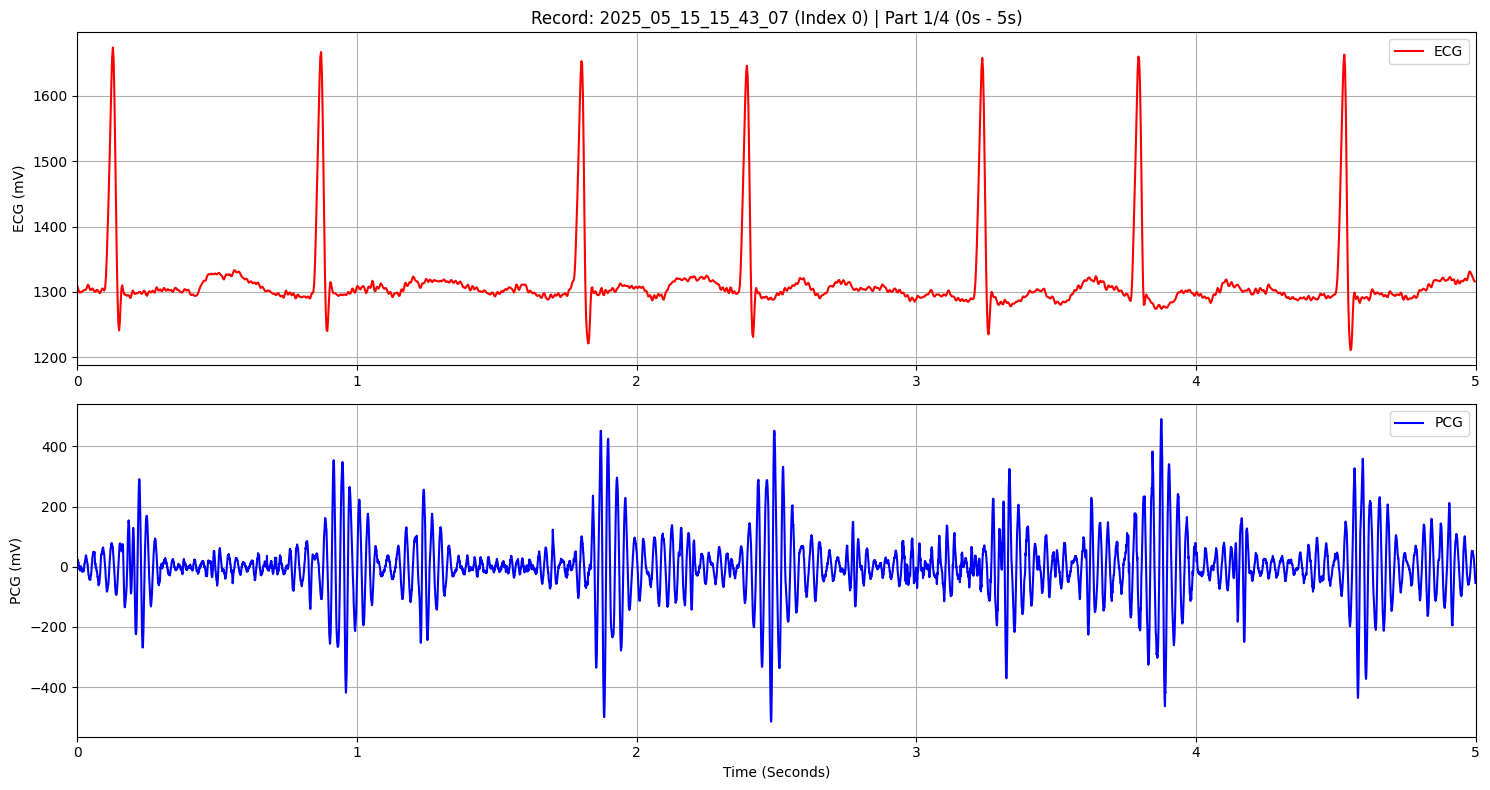

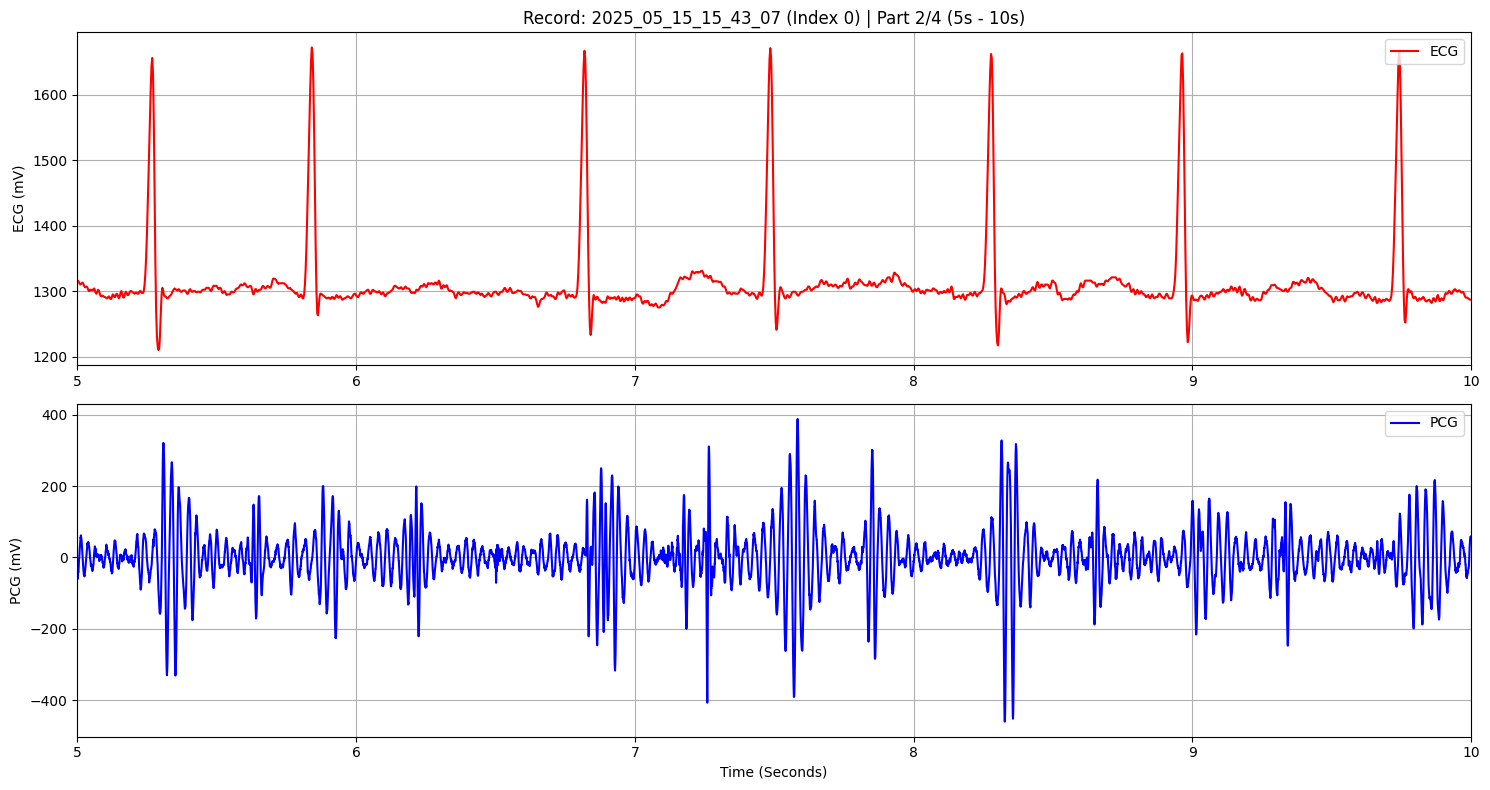

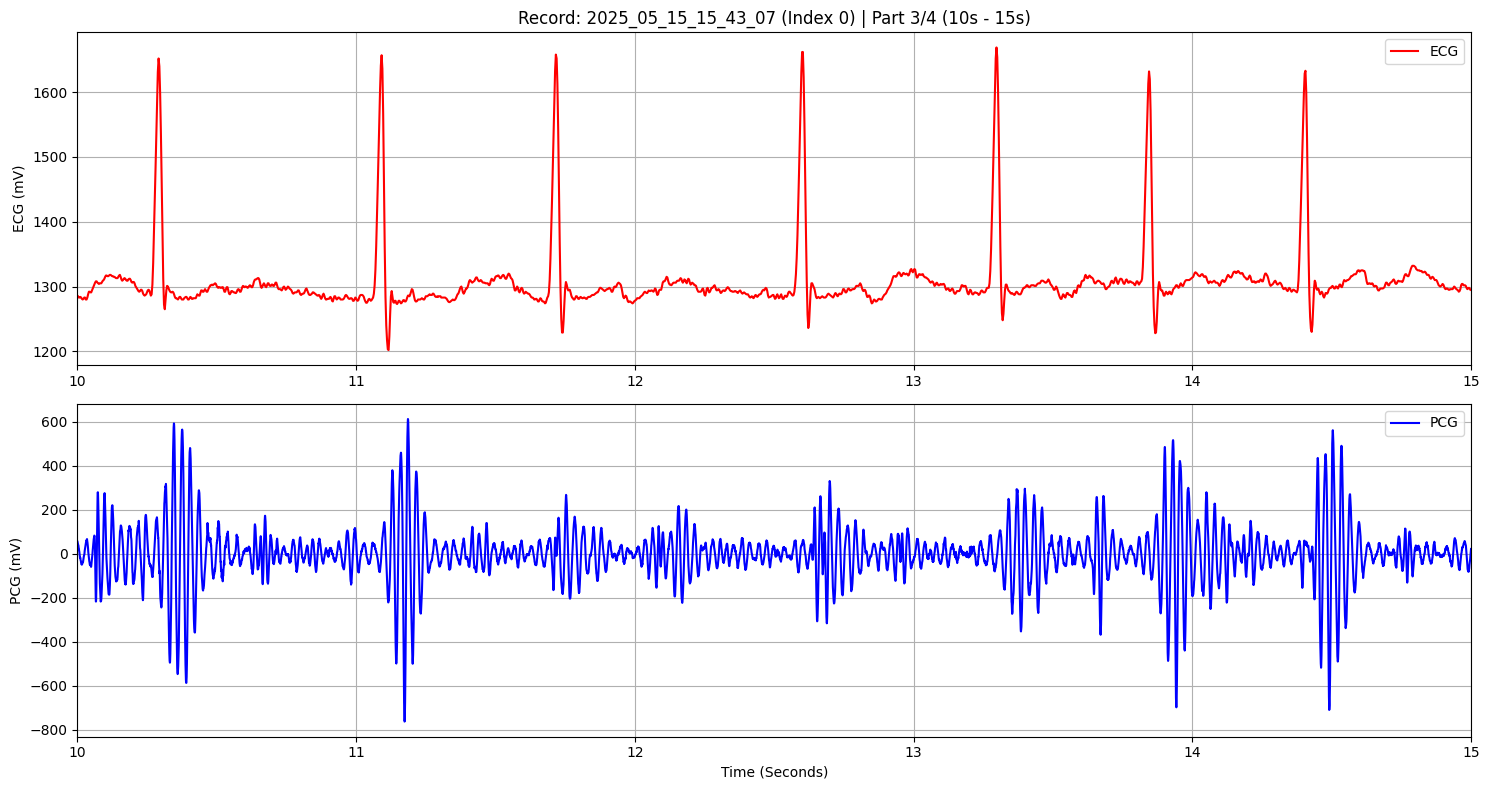

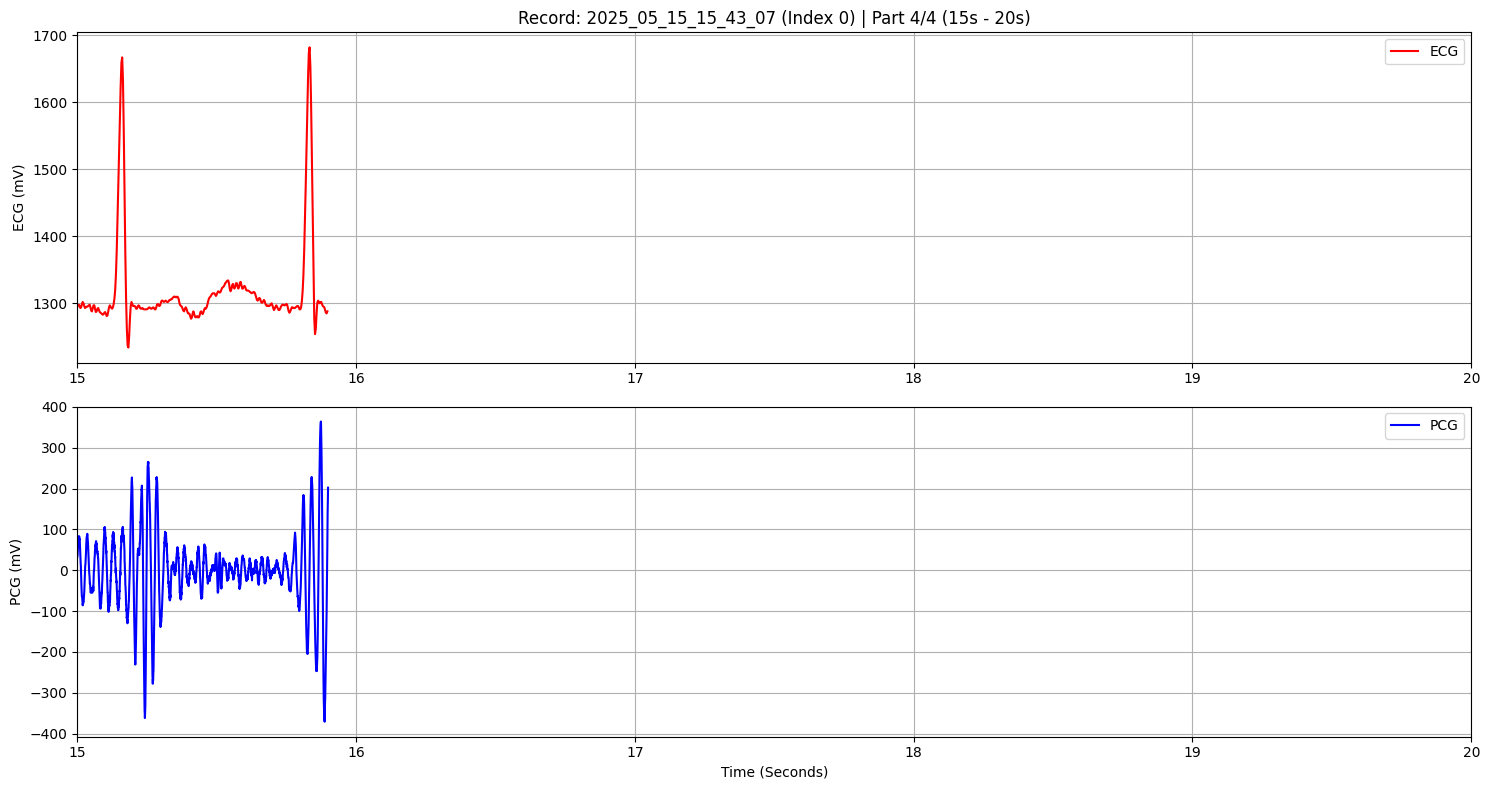

✅ Record 2025_05_15_15_43_07 檢查完畢。

🔄 正在處理 Index: 1 ...
📊 [ECG] Fs: 360 Hz | 時長: 15.90s
📊 [PCG] Fs: 1950 Hz | 時長: 15.90s
📈 開始繪圖 (共 4 個分頁)...


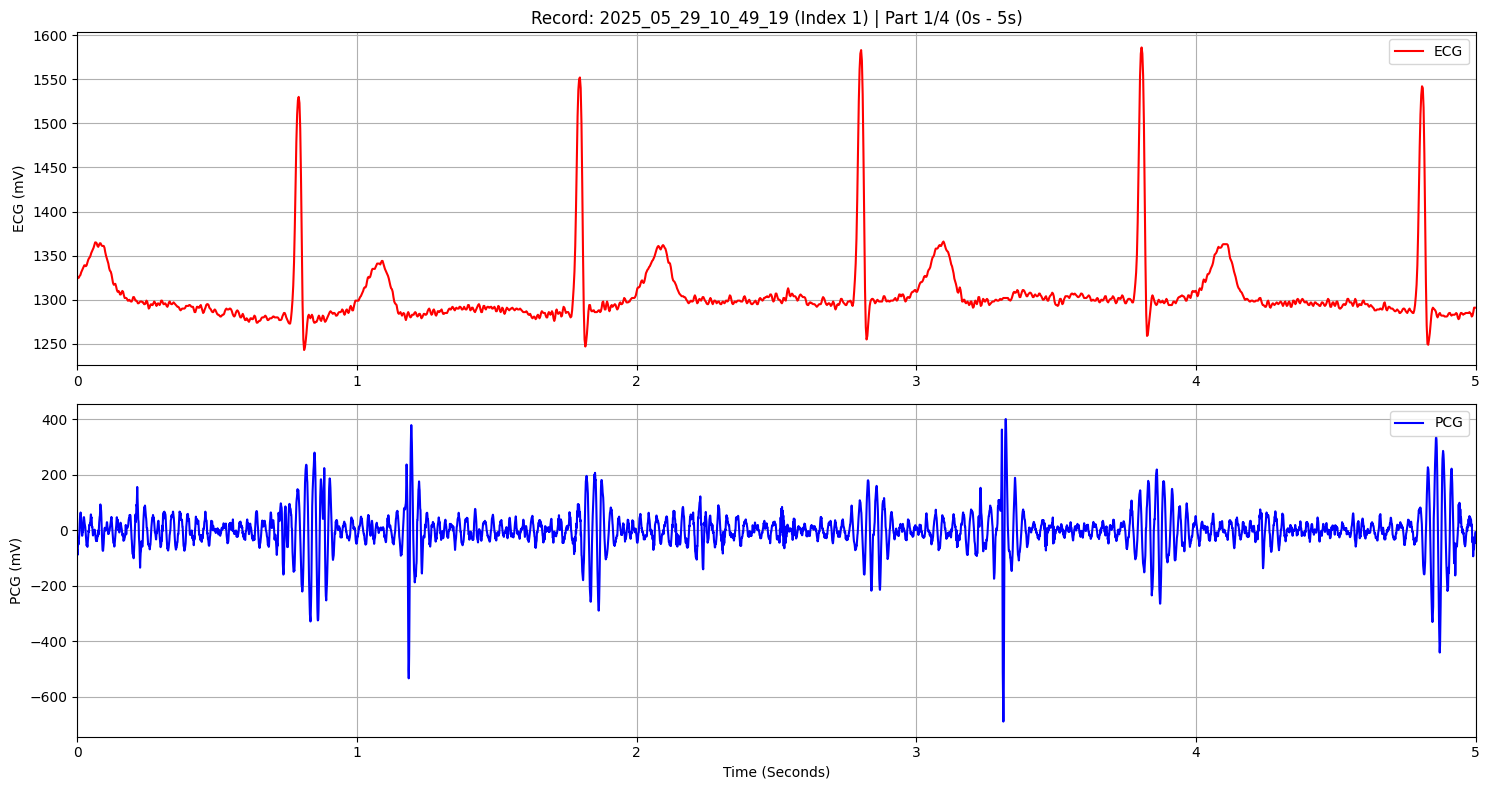

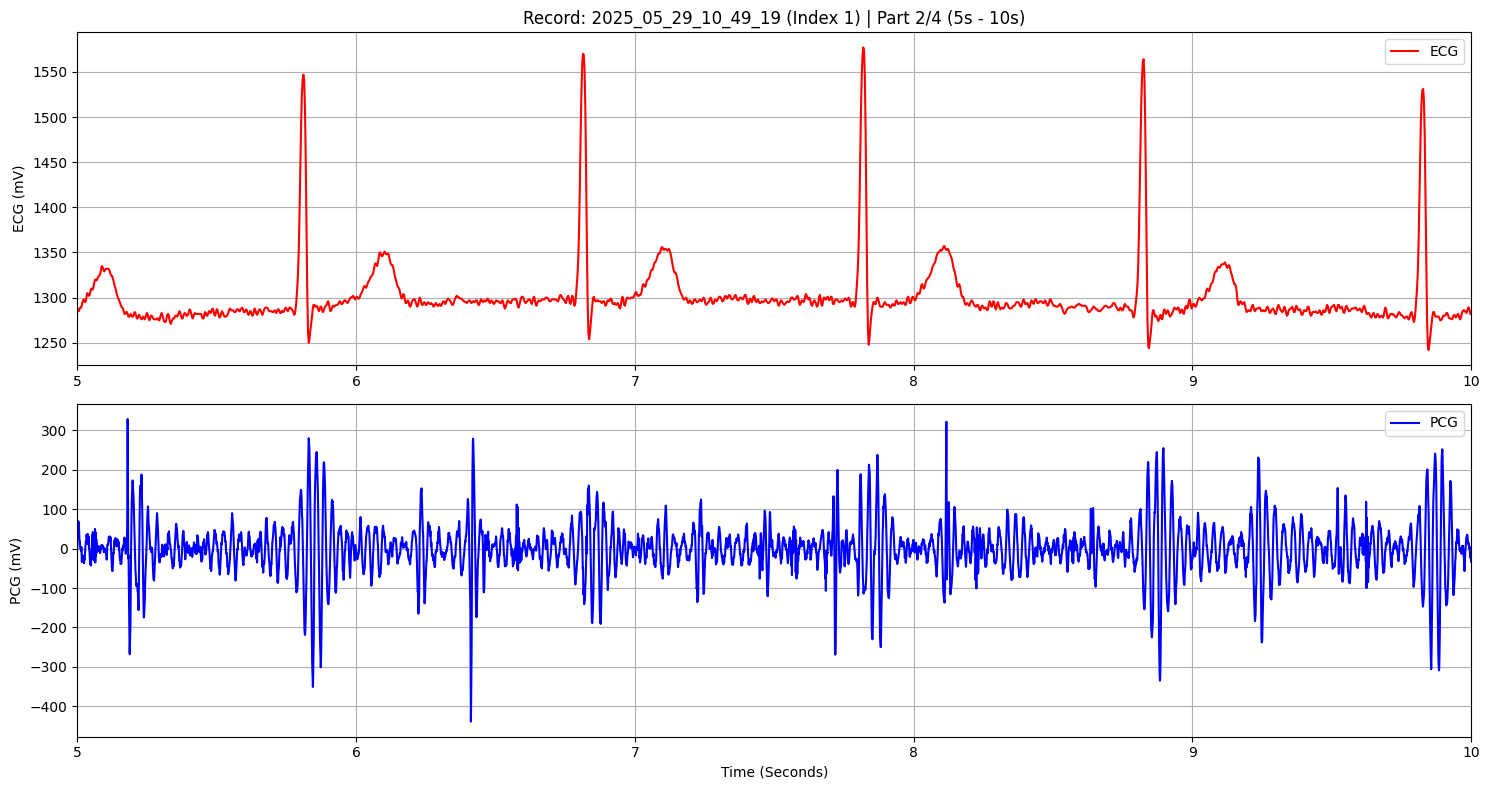

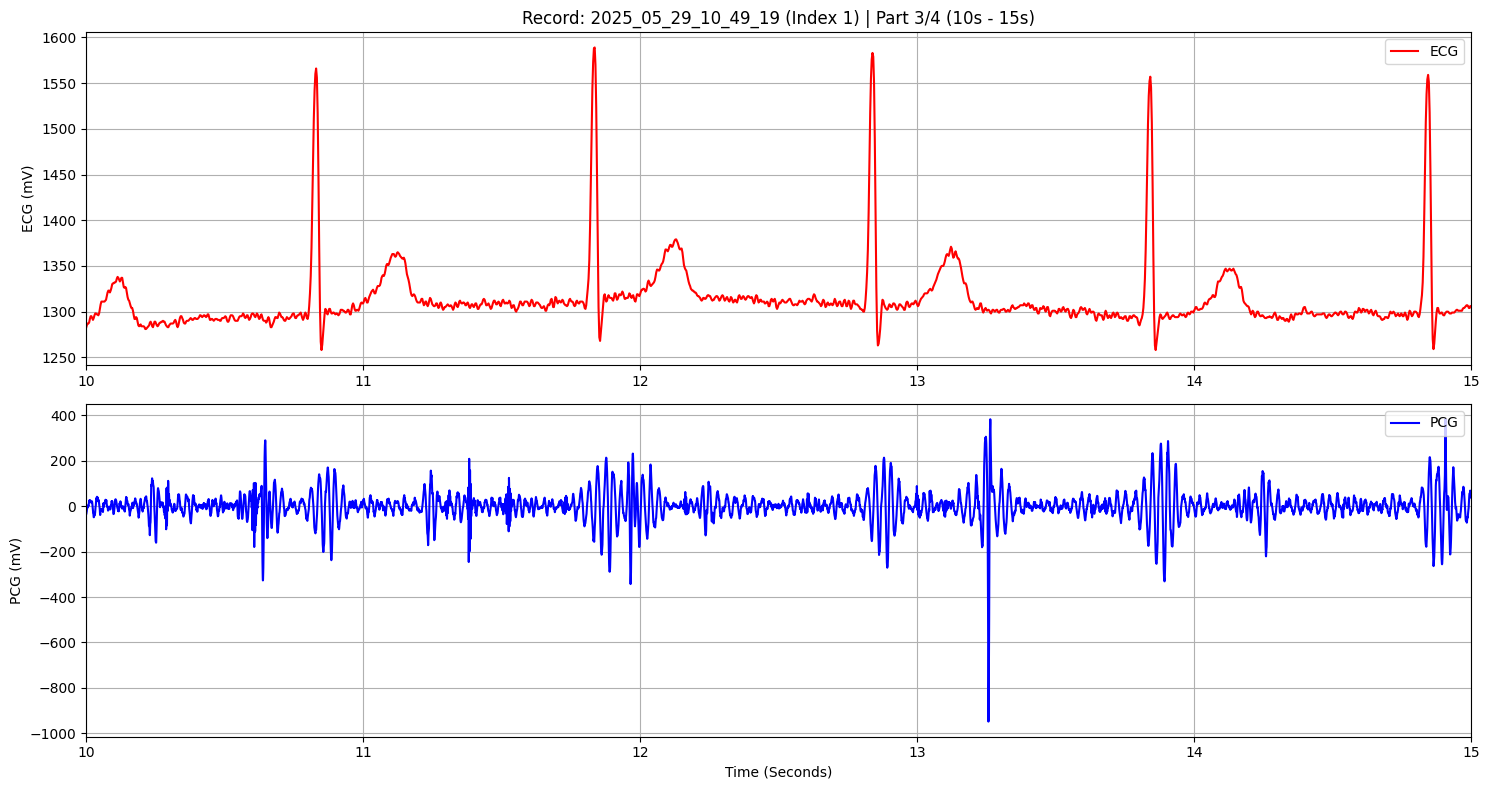

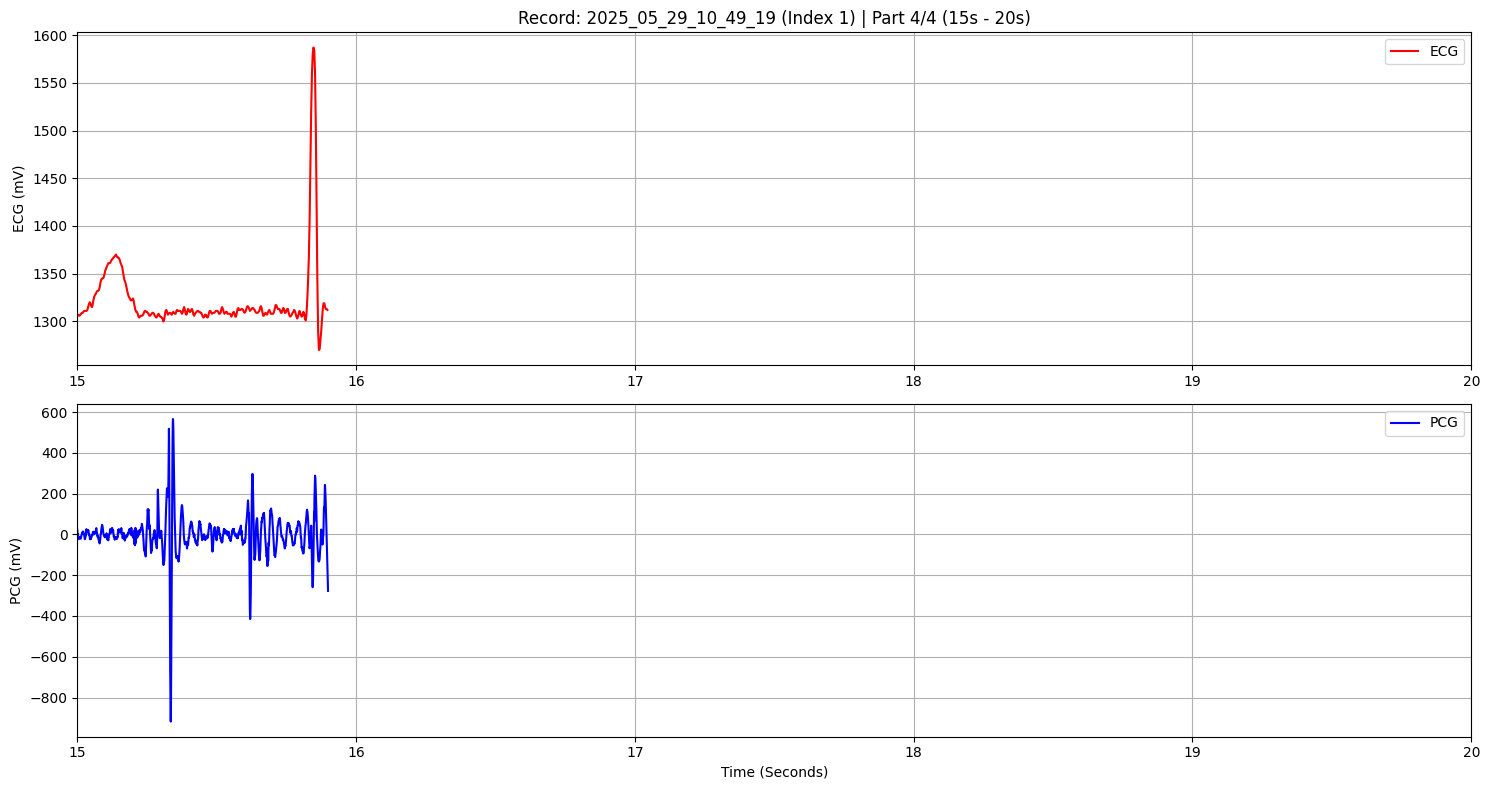

✅ Record 2025_05_29_10_49_19 檢查完畢。

🔄 正在處理 Index: 2 ...
📊 [ECG] Fs: 360 Hz | 時長: 14.90s
📊 [PCG] Fs: 1950 Hz | 時長: 14.90s
📈 開始繪圖 (共 3 個分頁)...


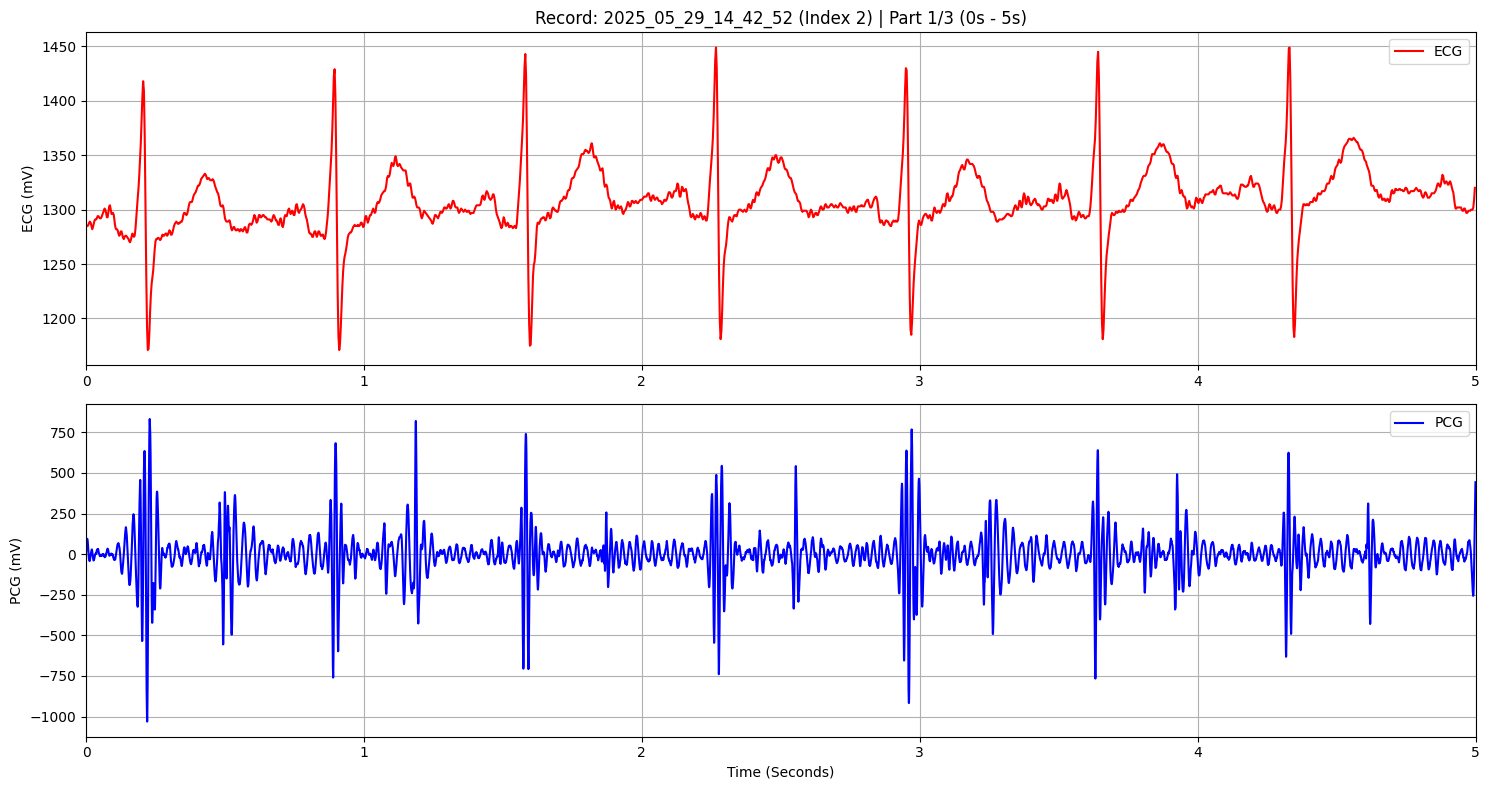

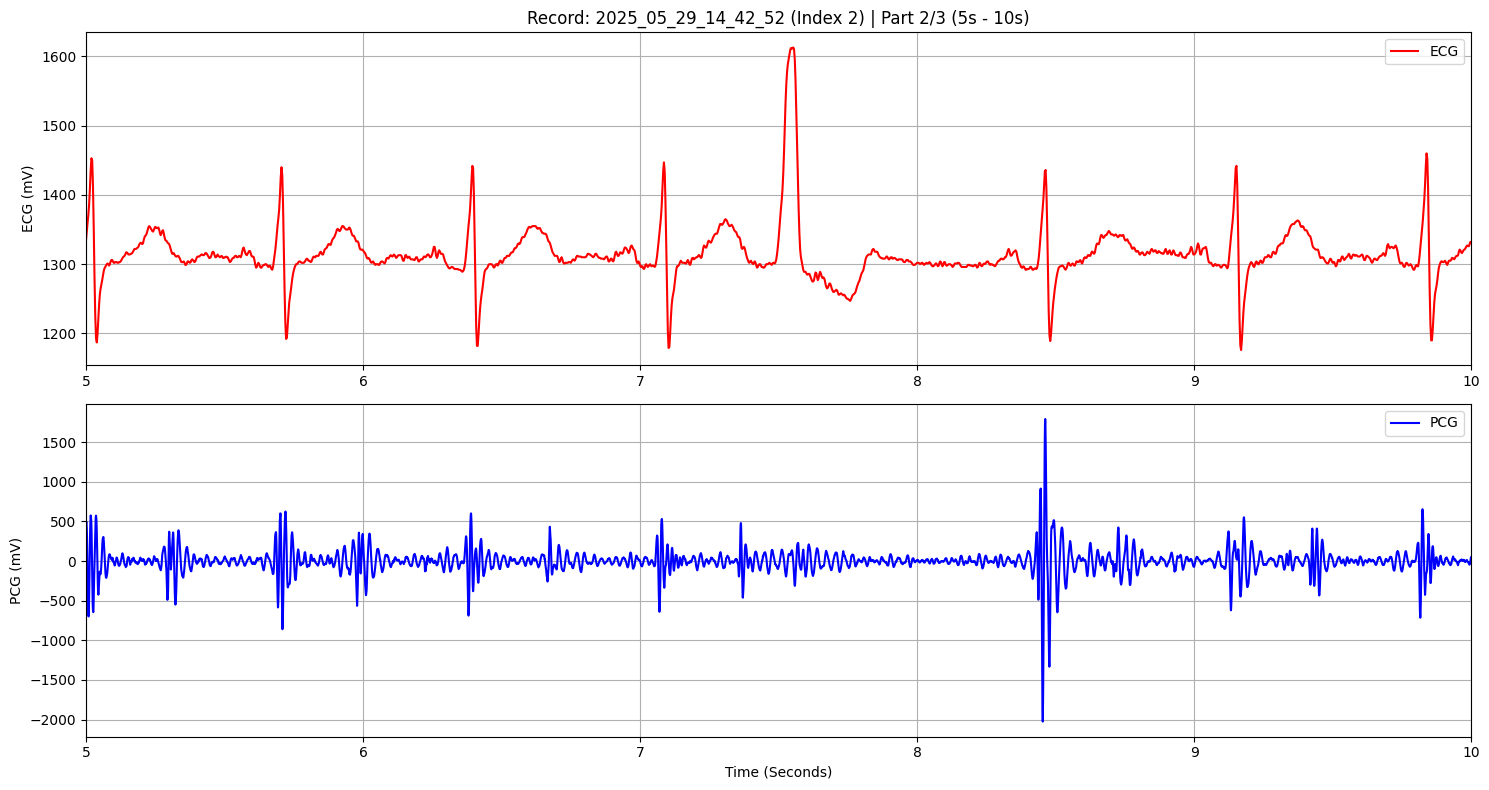

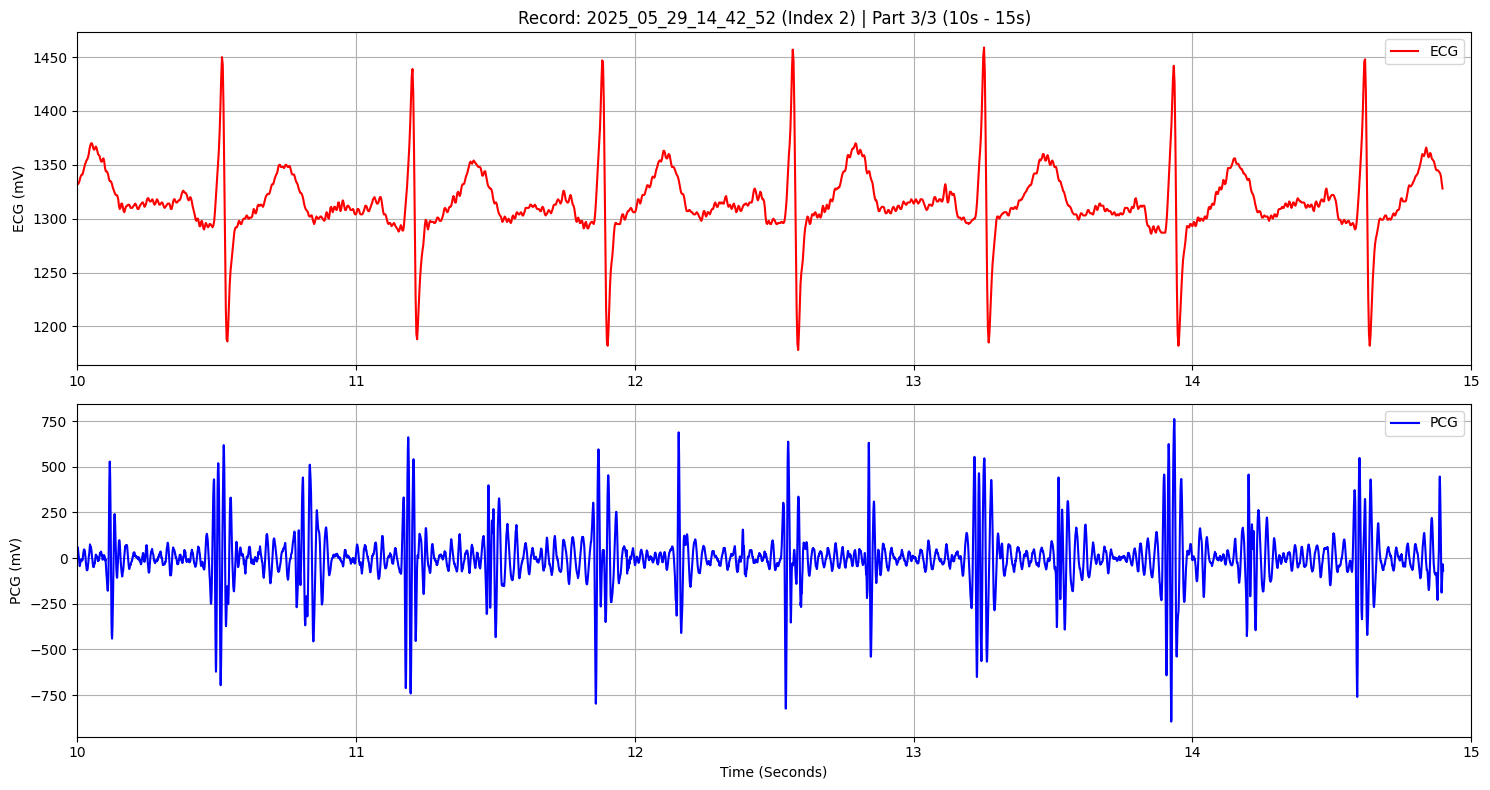

✅ Record 2025_05_29_14_42_52 檢查完畢。

🎉 所有指定資   完畢！


In [16]:
 

if __name__ == "__main__":
    # [修改點 2] 在這裡直接輸入你想跑的參數
    # 格式: (起始Index, 檢查筆數, 每頁秒數)
    verify_multiple_records_fixed_axis(start_index=start_index_a, check_count=check_count_a,chunk_size= chunk_size_a)
 